# Tema 7, Exercițiul 2
## Compararea a două tratamente (timpi de recuperare)

### Notații

- $X^{(A)}_i \mid \lambda_A \sim \text{Exponential}(\lambda_A)$, $X^{(B)}_j \mid \lambda_B \sim \text{Exponential}(\lambda_B)$: timpii de recuperare (zile);
- $\lambda_A, \lambda_B$: parametri de rată; timpii medii de recuperare sunt $1/\lambda_A$ și $1/\lambda_B$;
- prior independent $\lambda_A, \lambda_B \sim \text{Gamma}(2, 4)$ (formă rată), cu media $2/4 = 0.5$.

Un $\lambda$ mare înseamnă recuperare rapidă (timp mediu mic). Priorul Gamma(2, 4) pe rată corespunde unui timp mediu a priori în jur de $2$ zile.

PyMC: `chains=4`, `draws=2000` per lanț (`tune=2000`), `random_seed=42`.

## a) Modelul în PyMC și eșantioane din posteriorul lui $\lambda_A, \lambda_B$

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

A = np.array([3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9])
B = np.array([2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7])

with pm.Model() as model:
    lamA = pm.Gamma("lamA", alpha=2, beta=4)   # prior pe rata, tratament A
    lamB = pm.Gamma("lamB", alpha=2, beta=4)   # prior pe rata, tratament B
    pm.Exponential("xA", lam=lamA, observed=A)
    pm.Exponential("xB", lam=lamB, observed=B)
    mA = pm.Deterministic("mA", 1 / lamA)      # timp mediu A
    mB = pm.Deterministic("mB", 1 / lamB)      # timp mediu B
    idata = pm.sample(2000, tune=2000, chains=4, random_seed=42)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [lamA, lamB]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


In [2]:
print(az.summary(idata, var_names=["lamA", "lamB"], ci_prob=0.95))

       mean     sd eti95_lb eti95_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
lamA  0.293  0.094     0.14      0.5     7514     4896  1.00    0.0011  0.0011
lamB   0.38  0.118     0.18     0.65     7528     5036  1.00    0.0013  0.0015


Valorile `r_hat` $\approx 1$ și ESS mari arată că lanțurile au convers. Rata $\lambda_B$ este estimată mai mare decât $\lambda_A$ (recuperare mai rapidă la B).

## b) Posteriorul timpilor medii $1/\lambda_A$, $1/\lambda_B$ și HDI 95%

timp mediu A: media = 3.80 zile, HDI 95% = [1.72, 6.40]
timp mediu B: media = 2.92 zile, HDI 95% = [1.29, 4.85]
medii empirice: A = 3.77, B = 2.79


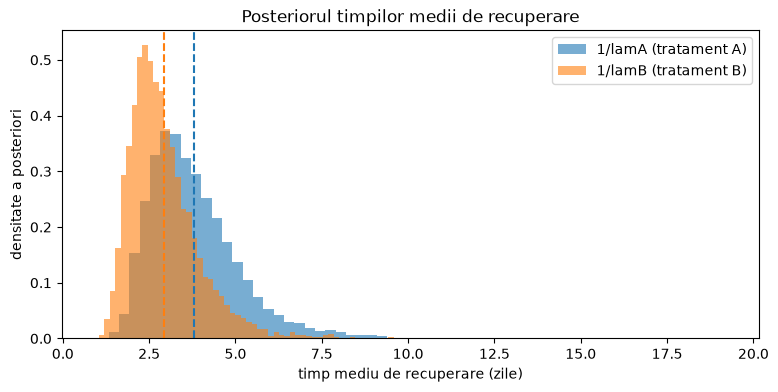

In [3]:
post = az.extract(idata)
mA_s = post["mA"].values
mB_s = post["mB"].values

hdiA = az.hdi(mA_s, prob=0.95)
hdiB = az.hdi(mB_s, prob=0.95)
print(f"timp mediu A: media = {mA_s.mean():.2f} zile, HDI 95% = [{hdiA[0]:.2f}, {hdiA[1]:.2f}]")
print(f"timp mediu B: media = {mB_s.mean():.2f} zile, HDI 95% = [{hdiB[0]:.2f}, {hdiB[1]:.2f}]")
print(f"medii empirice: A = {A.mean():.2f}, B = {B.mean():.2f}")

plt.figure(figsize=(9, 4))
plt.hist(mA_s, bins=60, density=True, alpha=0.6, label="1/lamA (tratament A)")
plt.hist(mB_s, bins=60, density=True, alpha=0.6, label="1/lamB (tratament B)")
plt.axvline(mA_s.mean(), color="C0", ls="--")
plt.axvline(mB_s.mean(), color="C1", ls="--")
plt.xlabel("timp mediu de recuperare (zile)")
plt.ylabel("densitate a posteriori")
plt.title("Posteriorul timpilor medii de recuperare")
plt.legend()
plt.show()

Posteriorul timpului mediu pentru B este deplasat spre valori mai mici decât al lui A, dar cele două distribuții se suprapun parțial.

## c) $P(\text{timp mediu}_B < \text{timp mediu}_A \mid \text{date})$

Compară parametrii (mediile populațiilor), ca fracțiune de eșantioane cu $1/\lambda_B < 1/\lambda_A$.

In [4]:
p_medii = (mB_s < mA_s).mean()
print(f"P(timp mediu B < timp mediu A | date) = {p_medii:.4f}")

P(timp mediu B < timp mediu A | date) = 0.7234


Cu probabilitate a posteriori de aproximativ $72\%$, tratamentul B are un timp mediu de recuperare mai mic decât A.

## d) Predicție: $P(\text{pacient nou B} < \text{pacient nou A})$

Aici comparăm două observații viitoare, câte un pacient nou din fiecare grup. Pentru fiecare eșantion a posteriori $(\lambda_A, \lambda_B)$ generăm câte un timp nou $\tilde X^{(A)} \sim \text{Exp}(\lambda_A)$, $\tilde X^{(B)} \sim \text{Exp}(\lambda_B)$ și estimăm fracțiunea cu $\tilde X^{(B)} < \tilde X^{(A)}$.

In [5]:
lamA_s = post["lamA"].values
lamB_s = post["lamB"].values

rng = np.random.default_rng(42)
newA = rng.exponential(1 / lamA_s)   # un pacient nou A per esantion a posteriori
newB = rng.exponential(1 / lamB_s)   # un pacient nou B per esantion a posteriori

p_pred = (newB < newA).mean()
print(f"P(pacient nou B se recupereaza mai repede ca A) = {p_pred:.4f}")
print(f"(comparatie) P(timp mediu B < timp mediu A)     = {p_medii:.4f}")

P(pacient nou B se recupereaza mai repede ca A) = 0.5547
(comparatie) P(timp mediu B < timp mediu A)     = 0.7234


Probabilitatea de la c), $\approx 0.72$, compară mediile populațiilor.

Probabilitatea predictivă de la d), $\approx 0.55$, este mai apropiată de $0.5$ pentru că include și variabilitatea individuală: chiar dacă B are în medie recuperare mai rapidă, timpii exponențiali ai doi pacienți concreți se suprapun mult, așa că un pacient B oarecare îl depășește pe unul A puțin.